
# Assignment 2 — Nhiệm vụ B (Chương 6): Phân phối liên tục và Gauss

**Dữ liệu:** UCI Seeds (ID 236), gồm 210 mẫu, 7 đặc trưng số thực và nhãn phân loại 3 giống lúa mì.

**Cặp đặc trưng được chọn:**
- X = Compactness
- Y = Kernel_Width

**Quy ước:** Sử dụng dữ liệu liên tục gốc, không rời rạc hóa và không chuẩn hóa thêm. Ma trận hiệp phương sai được tính với mẫu số N.

**Mục tiêu:** Ước lượng phân phối Gaussian hai chiều, xác định phân phối biên, phân phối có điều kiện, trực quan hóa mật độ Gaussian và nghiên cứu hỗn hợp hai phân phối Gaussian.

**Cách chạy:** Đặt file `seeds_dataset.txt` cùng thư mục với notebook và chạy các cell theo thứ tự từ trên xuống.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tên các cột giống phần A
COLS = [
    "Area", "Perimeter", "Compactness",
    "Kernel_Length", "Kernel_Width",
    "Asymmetry", "Groove_Length", "Class"
]

# Đọc dữ liệu Seeds
df = pd.read_csv(
    "seeds_dataset.txt",
    sep=r"\s+",
    header=None,
    names=COLS
)

print("Kích thước dữ liệu:", df.shape)
print("\n5 dòng đầu tiên:")
display(df.head())

print("\nGiá trị thiếu:", df.isna().sum().sum())


Kích thước dữ liệu: (210, 8)

5 dòng đầu tiên:


,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry,Groove_Length,Class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1



Giá trị thiếu: 0



## Bước 0 — Chuẩn bị dữ liệu và chọn cặp (X, Y)

**Đề bài.** Sử dụng hai đặc trưng số đã được lựa chọn trong Nhiệm vụ A để thực hiện các phép tính trên phân phối liên tục.

**Lời giải.**

Sử dụng bộ dữ liệu UCI Seeds với N = 210 mẫu.

Hai biến được chọn là:

- X = Compactness: Độ đặc chắc của hạt.
- Y = Kernel_Width: Chiều rộng của hạt.

Hai đặc trưng này có hệ số tương quan Pearson trên dữ liệu liên tục khoảng r = 0.7616, thể hiện mối tương quan dương rõ rệt.

Trong Nhiệm vụ B, sử dụng giá trị liên tục ban đầu của X và Y, không sử dụng các mức thấp, trung bình, cao từ Nhiệm vụ A.


In [2]:

# Giữ đúng cặp đặc trưng phần A
PAIR = ("Compactness", "Kernel_Width")

XN, YN = PAIR

X = df[XN].to_numpy()
Y = df[YN].to_numpy()

# Ma trận dữ liệu liên tục
Z = np.column_stack((X, Y))

N = len(Z)

print("X =", XN)
print("Y =", YN)
print("N =", N)
print("\n5 mẫu đầu tiên:")
print(Z[:5])


X = Compactness
Y = Kernel_Width
N = 210

5 mẫu đầu tiên:
[[0.871  3.312 ]
 [0.8811 3.333 ]
 [0.905  3.337 ]
 [0.8955 3.379 ]
 [0.9034 3.562 ]]



## B1 — Ước lượng vector trung bình và ma trận hiệp phương sai

**Đề bài.** Với hai đặc trưng đã chọn, ước lượng vector trung bình $\mu$ và ma trận hiệp phương sai $\Sigma$ theo công thức sử dụng mẫu số $N$. Báo cáo kết quả.

**Lời giải.**

Xét hai đặc trưng:

- $X$: Compactness
- $Y$: Kernel_Width

Tổng số mẫu là $N = 210$.

**1. Vector trung bình**

Vector trung bình được xác định bởi:

$$
\mu =
\begin{bmatrix}
\mu_X\\
\mu_Y
\end{bmatrix}
$$

Trong đó:

$$
\mu_X = \frac{1}{N}\sum_{i=1}^{N}x_i
$$

$$
\mu_Y = \frac{1}{N}\sum_{i=1}^{N}y_i
$$

Thay số từ dữ liệu:

$$
\mu_X = \frac{182.9097}{210} = 0.87099857
$$

$$
\mu_Y = \frac{684.307}{210} = 3.25860476
$$

Vậy:

$$
\boxed{
\mu =
\begin{bmatrix}
0.87099857\\
3.25860476
\end{bmatrix}
}
$$

**2. Ma trận hiệp phương sai**

Công thức:

$$
\Sigma =
\frac{1}{N}
\sum_{i=1}^{N}
(z_i-\mu)(z_i-\mu)^T
$$

Với $z_i=(x_i,y_i)^T$.

Ma trận hiệp phương sai có dạng:

$$
\Sigma =
\begin{bmatrix}
\Sigma_{xx} & \Sigma_{xy}\\
\Sigma_{xy} & \Sigma_{yy}
\end{bmatrix}
$$

Tính từng thành phần:

Phương sai của X:

$$
\Sigma_{xx}
=\frac{1}{210}\sum_{i=1}^{210}(x_i-\mu_X)^2
=\frac{0.11669501}{210}
\approx 0.000555691
$$

Phương sai của Y:

$$
\Sigma_{yy}
=\frac{1}{210}\sum_{i=1}^{210}(y_i-\mu_Y)^2
=\frac{29.81765420}{210}
\approx 0.141988830
$$

Hiệp phương sai của X và Y:

$$
\Sigma_{xy}
=\frac{1}{210}\sum_{i=1}^{210}
(x_i-\mu_X)(y_i-\mu_Y)
$$

$$
\Sigma_{xy}
=\frac{1.42072328}{210}
\approx 0.006765349
$$

Vậy ma trận hiệp phương sai là:

$$
\boxed{
\Sigma =
\begin{bmatrix}
0.000555691 & 0.006765349\\
0.006765349 & 0.141988830
\end{bmatrix}
}
$$

Kết quả được kiểm chứng bằng Python với hàm `numpy.cov` sử dụng `bias=True` để bảo đảm chia cho N.


In [3]:

# B1 - Mean Vector and Covariance Matrix

# Tính vector trung bình
mu = np.mean(Z, axis=0)

# Tính ma trận hiệp phương sai (chia N)
Z_centered = Z - mu
Sigma = (Z_centered.T @ Z_centered) / N

# Kiểm tra bằng numpy
Sigma_check = np.cov(Z, rowvar=False, bias=True)

print("Mean vector:")
print(mu)

print("\nCovariance matrix:")
print(Sigma)

print("\nVerification:",
      np.allclose(Sigma, Sigma_check))


Mean vector:
[0.87099857 3.25860476]

Covariance matrix:
[[0.00055569 0.00676535]
 [0.00676535 0.14198883]]

Verification: True



**Nhận xét B1:**

- Vector trung bình của hai đặc trưng là $\mu_X \approx 0.8710$ và $\mu_Y \approx 3.2586$.

- Phương sai của Compactness là 0.000556, trong khi phương sai của Kernel_Width là 0.141989. Điều này cho thấy Kernel_Width có độ phân tán tuyệt đối lớn hơn trên thang đo riêng của nó.

- Hiệp phương sai giữa hai đặc trưng là 0.006765 > 0, cho thấy Compactness và Kernel_Width có xu hướng biến thiên cùng chiều.

- Kết quả phù hợp với hệ số tương quan Pearson r ≈ 0.7616 trên dữ liệu liên tục đã xác định ở Nhiệm vụ A.

- Ma trận hiệp phương sai được tính với mẫu số N = 210, đúng quy ước của đề bài. Kết quả cũng trùng với hàm `numpy.cov(bias=True)`.



## B2 — Phân phối biên của Y

**Đề bài.** Giả sử $(X,Y)\sim\mathcal{N}(\mu,\Sigma)$. Xác định phân phối biên của $Y$ bằng cách đọc các thành phần tương ứng trong vector trung bình và ma trận hiệp phương sai. Giải thích vì sao không cần tính tích phân.

**Lời giải.**

Từ kết quả B1, ta có:

$$
\mu =
\begin{bmatrix}
0.87099857\\
3.25860476
\end{bmatrix}
$$

$$
\Sigma =
\begin{bmatrix}
0.000555691 & 0.006765349\\
0.006765349 & 0.141988830
\end{bmatrix}
$$

Với phân phối Gaussian hai chiều:

$$
(X,Y)\sim\mathcal{N}(\mu,\Sigma)
$$

Phân phối biên của $Y$ cũng là phân phối Gaussian một chiều:

$$
Y\sim\mathcal{N}(\mu_Y,\Sigma_{yy})
$$

Từ vector trung bình và ma trận hiệp phương sai:

$$
\mu_Y=3.25860476
$$

$$
\Sigma_{yy}=0.141988830
$$

Do đó, phân phối biên của $Y$ là:

$$
\boxed{
Y\sim\mathcal{N}(3.25860476,\ 0.141988830)
}
$$

**Giải thích vì sao không cần tính tích phân.**

Phân phối Gaussian đa chiều có tính chất đóng dưới phép lấy phân phối biên. Nghĩa là khi chỉ xét một hoặc một số thành phần của vector Gaussian, các thành phần đó vẫn tuân theo phân phối Gaussian.

Vì vậy, để xác định phân phối biên của $Y$, chỉ cần lấy giá trị trung bình $\mu_Y$ và phương sai $\Sigma_{yy}$ từ các vị trí tương ứng, không cần thực hiện phép tích phân mật độ đồng thời theo $X$.


In [4]:

# B2 - Marginal Distribution of Y

# Lấy trung bình và phương sai của Y từ B1
mu_Y = mu[1]
var_Y = Sigma[1, 1]

# Độ lệch chuẩn của Y
std_Y = np.sqrt(var_Y)

print("B2 - Marginal Distribution of Y")
print(f"Mean of Y: {mu_Y:.8f}")
print(f"Variance of Y: {var_Y:.9f}")
print(f"Standard deviation of Y: {std_Y:.8f}")

print("\nY ~ N(mu_Y, var_Y)")
print(f"Y ~ N({mu_Y:.8f}, {var_Y:.9f})")


B2 - Marginal Distribution of Y
Mean of Y: 3.25860476
Variance of Y: 0.141988830
Standard deviation of Y: 0.37681405

Y ~ N(mu_Y, var_Y)
Y ~ N(3.25860476, 0.141988830)



**Nhận xét B2:**

- Phân phối biên của Kernel_Width (Y) là phân phối Gaussian một chiều với trung bình khoảng 3.2586 và phương sai khoảng 0.141989.

- Phân phối biên được xác định trực tiếp từ vector trung bình và ma trận hiệp phương sai đã ước lượng ở B1.

- Không cần tính tích phân vì phân phối biên của một vector Gaussian vẫn là Gaussian.

- Kết quả này được suy ra dưới giả thiết dữ liệu tuân theo phân phối Gaussian hai chiều, không có nghĩa dữ liệu thực tế chắc chắn tuân theo phân phối Gaussian.



## B3 — Phân phối có điều kiện của X khi Y = y0

**Đề bài.** Tính bằng tay phân phối có điều kiện $p(x\mid y=y_0)$, trong đó $y_0$ là phân vị 75% của $Y$. Xác định trung bình, phương sai có điều kiện và kiểm chứng rằng phương sai có điều kiện nhỏ hơn $\Sigma_{xx}$.

**Lời giải.**

Xét hai đặc trưng liên tục:

- $X$: Compactness
- $Y$: Kernel_Width

Giả sử:

$$
(X,Y)\sim\mathcal{N}(\mu,\Sigma)
$$

Từ câu B1:

$$
\mu=
\begin{bmatrix}
0.87099857\\
3.25860476
\end{bmatrix}
$$

$$
\Sigma=
\begin{bmatrix}
0.000555691 & 0.006765349\\
0.006765349 & 0.141988830
\end{bmatrix}
$$

### 1. Xác định phân vị 75% của Y

Từ dữ liệu gốc gồm 210 mẫu, phân vị 75% của Kernel_Width là:

$$
y_0=Q_{75}(Y)=3.56175
$$

### 2. Công thức phân phối có điều kiện

Với phân phối Gaussian hai chiều:

$$
X\mid(Y=y_0)\sim\mathcal{N}(\mu_{X|Y},\sigma^2_{X|Y})
$$

Trung bình có điều kiện:

$$
\mu_{X|Y}
=\mu_X+\frac{\Sigma_{xy}}{\Sigma_{yy}}(y_0-\mu_Y)
$$

Phương sai có điều kiện:

$$
\sigma^2_{X|Y}
=\Sigma_{xx}-\frac{\Sigma_{xy}^2}{\Sigma_{yy}}
$$

### 3. Tính trung bình có điều kiện

Thay số:

$$
\mu_{X|Y}
=0.87099857+
\frac{0.006765349}{0.141988830}
(3.56175-3.25860476)
$$

$$
\mu_{X|Y}\approx0.88544255
$$

### 4. Tính phương sai có điều kiện

$$
\sigma^2_{X|Y}
=0.000555691-
\frac{(0.006765349)^2}{0.141988830}
$$

$$
\sigma^2_{X|Y}\approx0.000233342
$$

### 5. Kết quả phân phối có điều kiện

$$
\boxed{
X\mid(Y=3.56175)
\sim\mathcal{N}(0.88544255,\ 0.000233342)
}
$$

### 6. Kiểm tra phương sai

Phương sai ban đầu:

$$
\Sigma_{xx}=0.000555691
$$

Phương sai có điều kiện:

$$
\sigma^2_{X|Y}=0.000233342
$$

Do đó:

$$
0.000233342<0.000555691
$$

Vậy phương sai có điều kiện nhỏ hơn phương sai ban đầu, đúng yêu cầu đề bài.


In [5]:

# B3 - Conditional Gaussian Distribution

# 1. Tính phân vị 75% của Y
y0 = np.quantile(Y, 0.75)

# 2. Lấy các giá trị từ B1
mu_X, mu_Y = mu

sigma_xx = Sigma[0, 0]
sigma_xy = Sigma[0, 1]
sigma_yy = Sigma[1, 1]

# 3. Trung bình có điều kiện
conditional_mean = (
    mu_X + (sigma_xy / sigma_yy) * (y0 - mu_Y)
)

# 4. Phương sai có điều kiện
conditional_var = (
    sigma_xx - (sigma_xy ** 2 / sigma_yy)
)

# 5. Kiểm chứng
print("B3 - Conditional Gaussian Distribution")
print(f"75th percentile of Y: {y0:.6f}")
print(f"Conditional mean: {conditional_mean:.8f}")
print(f"Conditional variance: {conditional_var:.9f}")

print("\nVariance comparison:")
print(f"Original variance: {sigma_xx:.9f}")
print(f"Conditional variance: {conditional_var:.9f}")
print("Conditional variance < Original variance:",
      conditional_var < sigma_xx)


B3 - Conditional Gaussian Distribution
75th percentile of Y: 3.561750
Conditional mean: 0.88544255
Conditional variance: 0.000233342

Variance comparison:
Original variance: 0.000555691
Conditional variance: 0.000233342
Conditional variance < Original variance: True



**Nhận xét B3:**

- Phân vị 75% của Kernel_Width là 3.56175, được tính từ 210 mẫu dữ liệu gốc.

- Khi biết Kernel_Width bằng 3.56175, trung bình có điều kiện của Compactness tăng từ khoảng 0.8710 lên 0.8854.

- Phương sai có điều kiện giảm từ 0.000555691 xuống 0.000233342, tương đương mức giảm khoảng 58%.

- Điều này cho thấy việc biết giá trị Kernel_Width giúp giảm độ bất định khi dự đoán Compactness theo mô hình Gaussian hai chiều.

- Kết quả được kiểm chứng bằng Python và thỏa mãn điều kiện phương sai có điều kiện nhỏ hơn phương sai ban đầu.



## B4 — Biểu đồ tán xạ và đường mức Gaussian hai chiều

**Đề bài.** Vẽ trên cùng một hình biểu đồ tán xạ của dữ liệu và các đường mức mật độ Gaussian hai chiều đã ước lượng. Nhận xét mức độ phù hợp của giả thiết Gaussian.

**Lời giải.**

Sử dụng hai đặc trưng liên tục từ bộ dữ liệu Seeds:

- $X$: Compactness
- $Y$: Kernel_Width

Tổng số mẫu là $N=210$.

Giả sử:

$$
(X,Y)\sim\mathcal{N}(\mu,\Sigma)
$$

Với vector trung bình và ma trận hiệp phương sai từ B1:

$$
\mu=
\begin{bmatrix}
0.87099857\\
3.25860476
\end{bmatrix}
$$

$$
\Sigma=
\begin{bmatrix}
0.000555691 & 0.006765349\\
0.006765349 & 0.141988830
\end{bmatrix}
$$

Mật độ Gaussian hai chiều có công thức:

$$
f(z)=\frac{1}{2\pi\sqrt{|\Sigma|}}
\exp\left(
-\frac{1}{2}(z-\mu)^T\Sigma^{-1}(z-\mu)
\right)
$$

Trong đó:

- $z=(x,y)^T$ là vector chứa hai đặc trưng.
- $\mu$ là vector trung bình.
- $\Sigma$ là ma trận hiệp phương sai.
- $|\Sigma|$ là định thức của ma trận hiệp phương sai.
- $\Sigma^{-1}$ là ma trận nghịch đảo.

Biểu đồ được xây dựng bằng cách:

1. Vẽ 210 điểm dữ liệu gốc dưới dạng scatter plot.
2. Tính mật độ Gaussian trên một lưới giá trị $(x,y)$.
3. Vẽ các đường mức Gaussian tại các mức xác suất 50%, 80% và 95%.
4. So sánh hình dạng các đường mức với sự phân bố thực tế của dữ liệu.


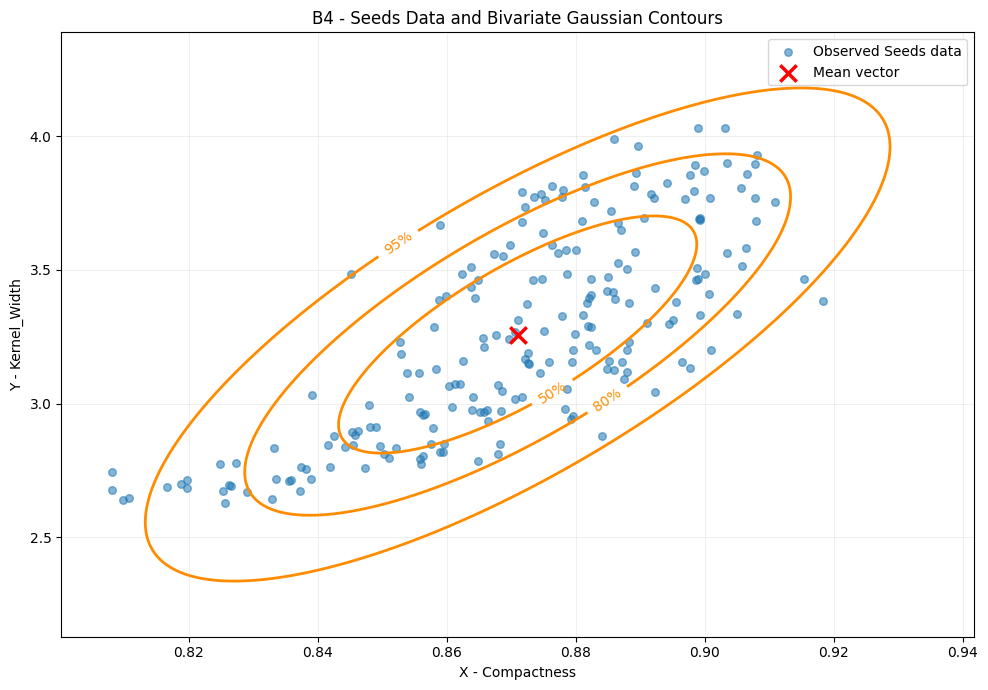

Empirical coverage:
50% ellipse: 40.95%
80% ellipse: 81.90%
95% ellipse: 97.14%


In [6]:

# B4 - Scatter Plot and Bivariate Gaussian Contours

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal, chi2

# 1. Độ lệch chuẩn từ ma trận hiệp phương sai
std_x = np.sqrt(Sigma[0, 0])
std_y = np.sqrt(Sigma[1, 1])

# 2. Tạo lưới bao phủ dữ liệu và đường mức Gaussian
x_min = min(X.min(), mu[0] - 3 * std_x)
x_max = max(X.max(), mu[0] + 3 * std_x)
y_min = min(Y.min(), mu[1] - 3 * std_y)
y_max = max(Y.max(), mu[1] + 3 * std_y)

x_grid = np.linspace(x_min, x_max, 250)
y_grid = np.linspace(y_min, y_max, 250)

XX, YY = np.meshgrid(x_grid, y_grid)
positions = np.dstack((XX, YY))

# 3. Mật độ Gaussian hai chiều
gaussian = multivariate_normal(mean=mu, cov=Sigma)
density = gaussian.pdf(positions)

# 4. Tính các mức mật độ tương ứng với
#    vùng xác suất 50%, 80%, 95%
probabilities = [0.95, 0.80, 0.50]

levels = [
    gaussian.pdf(mu) * np.exp(
        -chi2.ppf(p, df=2) / 2
    )
    for p in probabilities
]

# 5. Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(
    X, Y,
    alpha=0.55,
    s=30,
    label="Observed Seeds data"
)

contours = ax.contour(
    XX, YY, density,
    levels=levels,
    colors="darkorange",
    linewidths=2
)

# Nhãn các đường mức
labels = {
    levels[0]: "95%",
    levels[1]: "80%",
    levels[2]: "50%"
}

ax.clabel(
    contours,
    inline=True,
    fontsize=10,
    fmt=labels
)

# Đánh dấu vector trung bình
ax.scatter(
    mu[0], mu[1],
    marker="x",
    s=140,
    color="red",
    linewidths=2.5,
    label="Mean vector"
)

ax.set_xlabel("X - Compactness")
ax.set_ylabel("Y - Kernel_Width")
ax.set_title(
    "B4 - Seeds Data and Bivariate Gaussian Contours"
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

# 6. Lưu hình cho báo cáo Word
plt.savefig(
    "B4_Gaussian_Contours.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 7. Kiểm tra tỷ lệ mẫu nằm trong các elip
distance2 = np.sum(
    ((Z - mu) @ np.linalg.inv(Sigma)) * (Z - mu),
    axis=1
)

print("Empirical coverage:")
for p in [0.50, 0.80, 0.95]:
    threshold = chi2.ppf(p, df=2)
    coverage = np.mean(distance2 <= threshold)
    print(f"{int(p*100)}% ellipse: {coverage:.2%}")



**Nhận xét B4:**

- Biểu đồ tán xạ của 210 mẫu Seeds cho thấy Compactness và Kernel_Width có xu hướng biến thiên cùng chiều, phù hợp với hệ số tương quan Pearson khoảng 0.7616.

- Các đường mức Gaussian hai chiều có dạng elip nghiêng lên về bên phải, phản ánh hiệp phương sai dương giữa hai đặc trưng.

- Các vùng elip Gaussian 50%, 80% và 95% lần lượt chứa khoảng 40.95%, 81.90% và 97.14% số mẫu thực tế.

- Phân bố thực tế không hoàn toàn trùng với phân phối Gaussian lý thuyết. Một phần nguyên nhân có thể đến từ cấu trúc của bộ dữ liệu gồm ba giống lúa mì với những đặc điểm khác nhau.

- Nhìn chung, mô hình Gaussian hai chiều mô tả được xu hướng tương quan và sự phân tán chính của dữ liệu, nhưng chỉ mang tính xấp xỉ. Chỉ quan sát biểu đồ chưa đủ để khẳng định dữ liệu tuân theo Gaussian hai chiều.



## B5 — Hỗn hợp hai phân phối Gaussian một chiều

**Đề bài.** Xét hỗn hợp hai Gaussian một chiều:

$$
p(x)=\pi\mathcal{N}(\mu_1,\sigma_1^2)
+(1-\pi)\mathcal{N}(\mu_2,\sigma_2^2)
$$

Với tham số do nhóm tự chọn. Tính bằng tay $E[X]$ và $V[X]$, kiểm chứng bằng luật phương sai toàn phần, và giải thích vì sao phương sai hỗn hợp không chỉ bằng trung bình có trọng số của hai phương sai.

**Lời giải.**

### 1. Lựa chọn các tham số

Xét đặc trưng $X$ = Compactness của bộ dữ liệu Seeds.

Chọn hai thành phần Gaussian với các tham số minh họa:

| Tham số | Gaussian 1 | Gaussian 2 |
|---|---|---|
| Trọng số | 0.4 | 0.6 |
| Trung bình | 0.85 | 0.89 |
| Độ lệch chuẩn | 0.01 | 0.02 |
| Phương sai | 0.0001 | 0.0004 |

Các tham số do nhóm tự chọn, không phải kết quả ước lượng mô hình từ dữ liệu.

Khi đó:

$$
p(x)=0.4\mathcal{N}(0.85,0.0001)
+0.6\mathcal{N}(0.89,0.0004)
$$

### 2. Tính kỳ vọng E[X]

Kỳ vọng của hỗn hợp Gaussian được tính bởi:

$$
E[X]=\pi\mu_1+(1-\pi)\mu_2
$$

Thay số:

$$
E[X]=0.4(0.85)+0.6(0.89)
$$

$$
E[X]=0.34+0.534=0.874
$$

Vậy:

$$
\boxed{E[X]=0.874}
$$

### 3. Tính phương sai V[X]

Sử dụng công thức:

$$
V[X]=E[X^2]-(E[X])^2
$$

Đối với hỗn hợp hai Gaussian:

$$
E[X^2]=\pi(\sigma_1^2+\mu_1^2)
+(1-\pi)(\sigma_2^2+\mu_2^2)
$$

Thay số:

$$
E[X^2]=0.4(0.0001+0.85^2)
+0.6(0.0004+0.89^2)
$$

$$
E[X^2]=0.4(0.7226)+0.6(0.7925)
$$

$$
E[X^2]=0.28904+0.4755=0.76454
$$

Do đó:

$$
V[X]=0.76454-(0.874)^2
$$

$$
V[X]=0.76454-0.763876
$$

$$
\boxed{V[X]=0.000664}
$$

### 4. Kiểm chứng bằng luật phương sai toàn phần

Gọi $C$ là biến chỉ thành phần Gaussian được chọn.

Theo luật phương sai toàn phần:

$$
V[X]=E[V(X\mid C)]+V(E[X\mid C])
$$

**Phương sai trong từng thành phần:**

$$
E[V(X\mid C)]
=\pi\sigma_1^2+(1-\pi)\sigma_2^2
$$

$$
=0.4(0.0001)+0.6(0.0004)
$$

$$
=0.00028
$$

**Phương sai giữa các thành phần:**

$$
V(E[X\mid C])
=\pi(1-\pi)(\mu_1-\mu_2)^2
$$

$$
=0.4(0.6)(0.85-0.89)^2
$$

$$
=0.000384
$$

Vậy:

$$
V[X]=0.00028+0.000384
$$

$$
\boxed{V[X]=0.000664}
$$

Kết quả trùng với phương pháp tính trực tiếp từ $E[X^2]-(E[X])^2$.

### 5. Giải thích sự khác biệt về phương sai

Phương sai hỗn hợp có công thức:

$$
V[X]=\pi\sigma_1^2+(1-\pi)\sigma_2^2
+\pi(1-\pi)(\mu_1-\mu_2)^2
$$

Hai số hạng đầu thể hiện độ phân tán trong từng thành phần Gaussian.

Số hạng cuối thể hiện sự khác biệt giữa trung bình của hai thành phần.

Trong ví dụ này:

$$
\mu_1=0.85\ne0.89=\mu_2
$$

Nên:

$$
\pi(1-\pi)(\mu_1-\mu_2)^2=0.000384>0
$$

Do đó:

$$
V[X]=0.000664\ne0.00028
$$

Như vậy, phương sai của hỗn hợp lớn hơn trung bình có trọng số của hai phương sai vì còn chịu ảnh hưởng từ sự khác biệt giữa hai trung bình.


In [7]:

# B5 - Mixture of Two Gaussian Distributions

import numpy as np

# 1. Chọn tham số hỗn hợp
pi = 0.4

mu1 = 0.85
mu2 = 0.89

sigma1 = 0.01
sigma2 = 0.02

var1 = sigma1 ** 2
var2 = sigma2 ** 2

# 2. Tính kỳ vọng E[X]
E_X = pi * mu1 + (1 - pi) * mu2

# 3. Tính E[X^2]
E_X2 = (
    pi * (var1 + mu1**2)
    + (1 - pi) * (var2 + mu2**2)
)

# 4. Phương sai trực tiếp
V_X_direct = E_X2 - E_X**2

# 5. Luật phương sai toàn phần
# Phương sai trong các thành phần
within_variance = (
    pi * var1 + (1 - pi) * var2
)

# Phương sai giữa các thành phần
between_variance = (
    pi * (1 - pi) * (mu1 - mu2)**2
)

# Tổng phương sai
V_X_total = within_variance + between_variance

# 6. Kiểm tra kết quả
print("B5 - Gaussian Mixture")
print("-" * 40)

print(f"E[X] = {E_X:.6f}")
print(f"E[X^2] = {E_X2:.6f}")
print(f"V[X] (Direct) = {V_X_direct:.6f}")

print("\nLaw of Total Variance:")
print(f"Within variance = {within_variance:.6f}")
print(f"Between variance = {between_variance:.6f}")
print(f"Total variance = {V_X_total:.6f}")

print("\nVerification:")
print("Two methods match:",
      np.isclose(V_X_direct, V_X_total))

print("Variance differs from weighted average:",
      not np.isclose(V_X_total, within_variance))


B5 - Gaussian Mixture
----------------------------------------
E[X] = 0.874000
E[X^2] = 0.764540
V[X] (Direct) = 0.000664

Law of Total Variance:
Within variance = 0.000280
Between variance = 0.000384
Total variance = 0.000664

Verification:
Two methods match: True
Variance differs from weighted average: True



**Nhận xét B5:**

- Hỗn hợp gồm hai phân phối Gaussian một chiều với trọng số lần lượt là 0.4 và 0.6.

- Kỳ vọng của hỗn hợp là E[X] = 0.874, nằm giữa hai trung bình thành phần 0.85 và 0.89.

- Phương sai của hỗn hợp là V[X] = 0.000664, được tính bằng phương pháp E[X²] - (E[X])².

- Theo luật phương sai toàn phần, phương sai trong từng thành phần là 0.000280 và phương sai giữa các thành phần là 0.000384. Tổng hai giá trị bằng 0.000664, khớp với kết quả tính trực tiếp.

- Phương sai của hỗn hợp không chỉ bằng trung bình có trọng số của các phương sai thành phần vì hai Gaussian có trung bình khác nhau.

- Kết quả được kiểm chứng bằng Python, cho thấy hai phương pháp tính hoàn toàn nhất quán.

- Các tham số hỗn hợp được nhóm tự chọn để minh họa công thức, không phải tham số được ước lượng trực tiếp từ dữ liệu Seeds.



### 6. Giải thích vì sao phương sai hỗn hợp không chỉ bằng trung bình có trọng số của các phương sai

Phương sai của hỗn hợp Gaussian gồm hai thành phần: phương sai bên trong từng nhóm và phương sai do sự khác biệt giữa trung bình hai nhóm.

Theo luật phương sai toàn phần:

$$
V[X]=\pi\sigma_1^2+(1-\pi)\sigma_2^2+\pi(1-\pi)(\mu_1-\mu_2)^2
$$

Với các tham số đã chọn:

$$
V[X]=0.00028+0.000384=0.000664
$$

Trong khi đó:

$$
\pi\sigma_1^2+(1-\pi)\sigma_2^2=0.00028
$$

**Kết luận:** Vì hai Gaussian có trung bình khác nhau ($\mu_1=0.85$ và $\mu_2=0.89$), nên xuất hiện thêm thành phần phương sai giữa hai nhóm bằng $0.000384$. Do đó, phương sai của hỗn hợp không chỉ bằng trung bình có trọng số của hai phương sai thành phần.

Hai biểu thức chỉ bằng nhau khi $\mu_1=\mu_2$ (với $0<\pi<1$).
